# Icespec processing notebook
### Fall 24
Rumz

In [1]:
import warnings

In [2]:
#Importing Python Libraries and Packages

import pandas as pd
import numpy as np

import processing.set_icespec_path as tool
icespec_code_path=tool.add_icespec_code_dir()
tool.add_icespec_code_dir()
from icespec import icespec_process1_module as processice
from icespec import get_size_module as getSize

Use HSI_July2024 Spreadsheet for ID and section names

In [3]:
datasetPath = '/nfs/vortex/hsi_data/July24/' #path to data folder on computer or server

CoreID = "ALHIC 2302" #insert core name inside quotation marks
Section = "22 Sec 25" #insert Tube/section; Ex. '33 Sec 42' or '159_3 Q1'
Light = "Top" # Top vs Bottom Light; Top light gives reflectance data, Bottom light shows transparency


Debug = True

In [4]:
dataPath = processice.getDataPath(datasetPath, CoreID, Section, Light)

Dataset Path:  /Users/r.rumsey/src/DenaliData/ICF_DEN13A-227_0003


In [5]:
dataSize = [1500, 2000, 450, 500]
stdSize = [530, 820, 410, 620]

Spectral Environ:  /Users/r.rumsey/src/DenaliData/ICF_DEN13A-227_0003/capture
Data: (5118, 1024, 224), W ref: (196, 1024, 224), D ref: (100, 1024, 224)


/Applications/anaconda3/envs/HSIenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)


Trimmed shapes: (500, 50, 224),W_ref: (196, 50, 224),D_ref:(100, 50, 224)
Image refelectance calculated, reflectance file dimentions: (500, 50, 224)


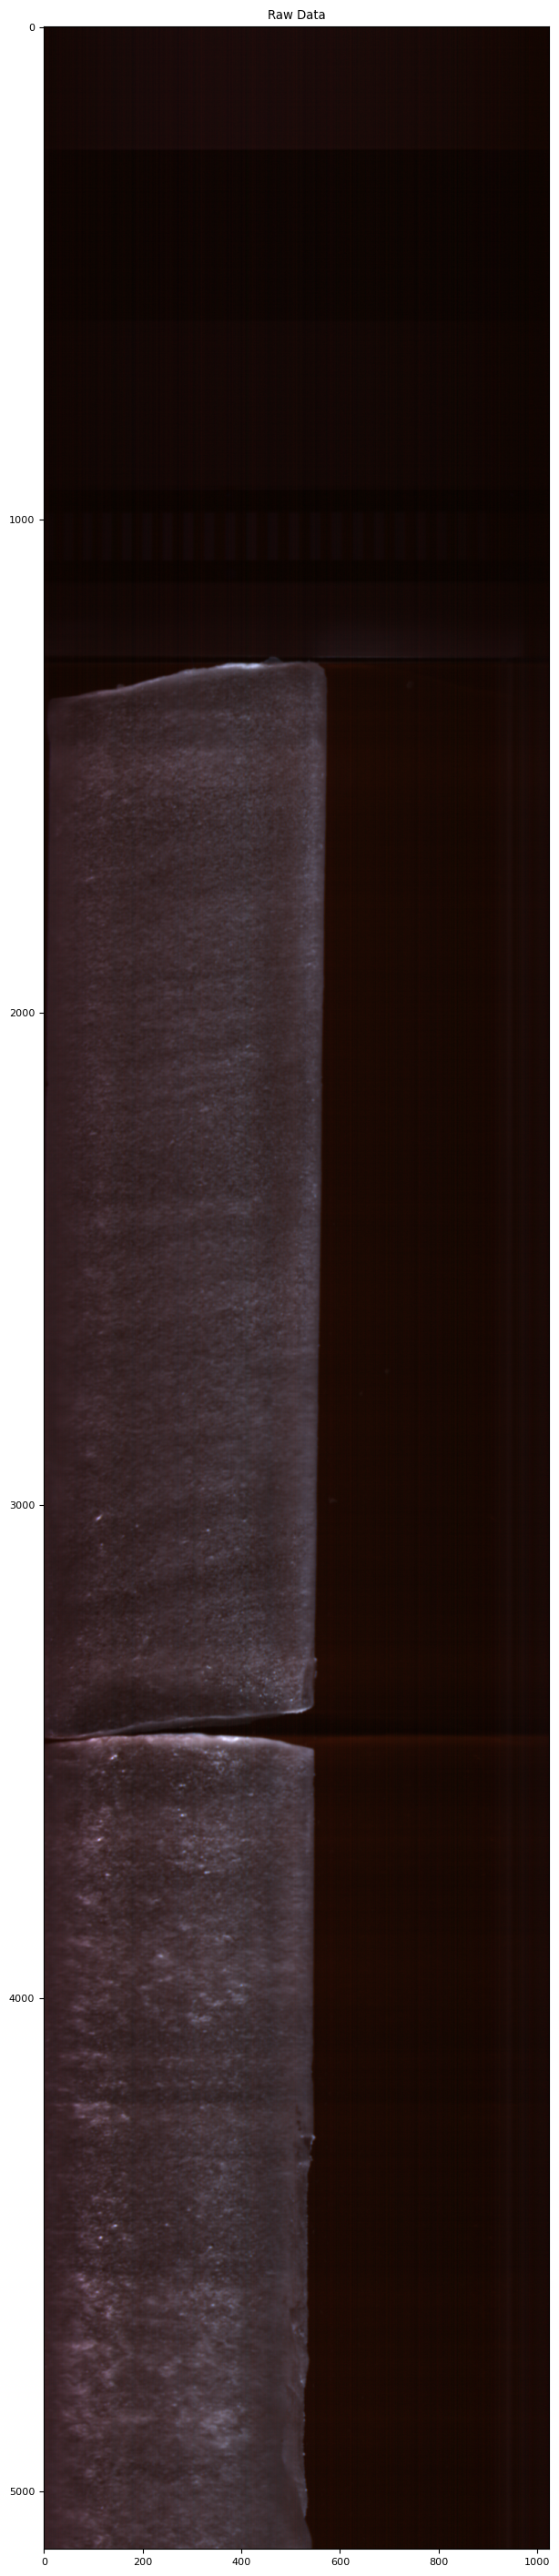

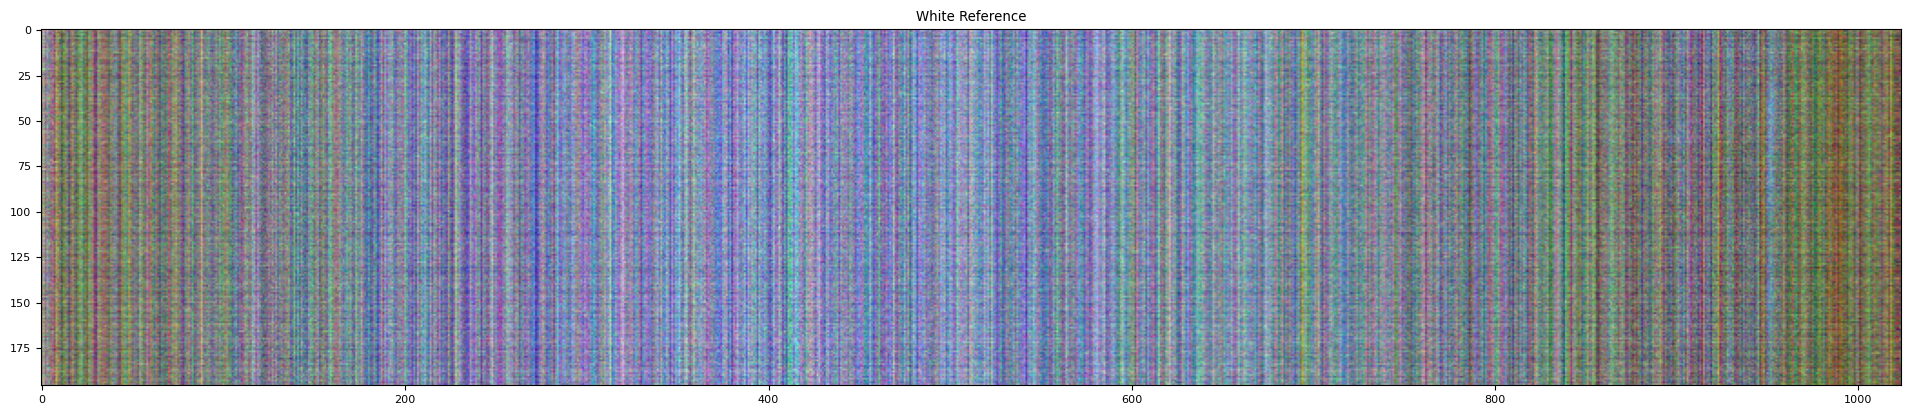

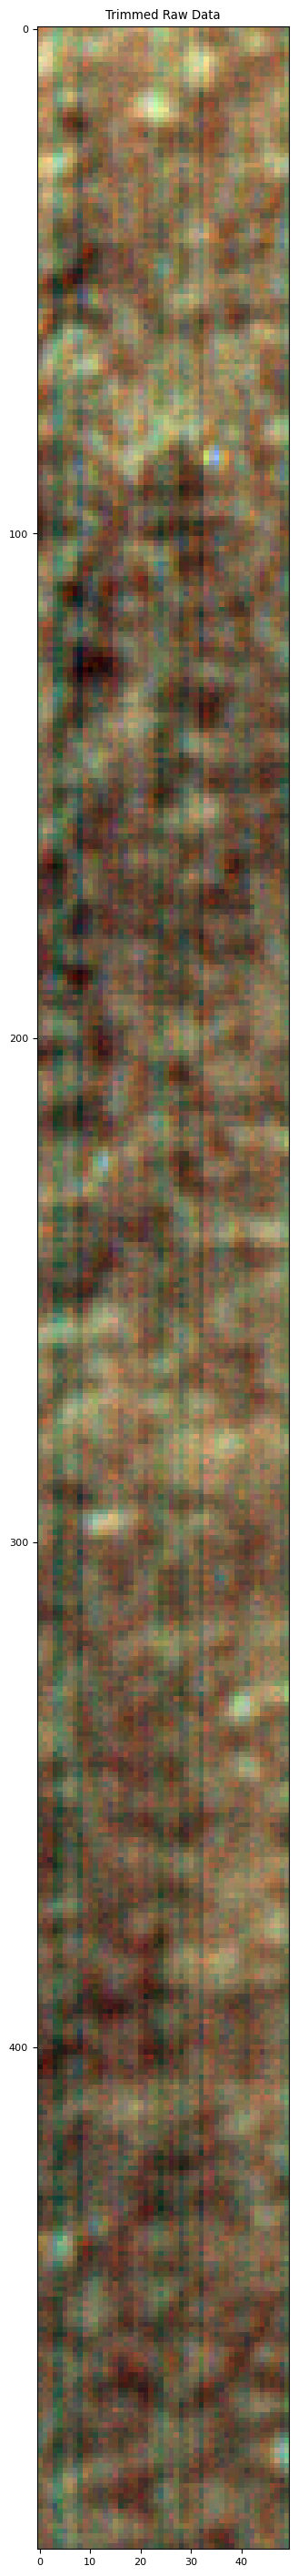

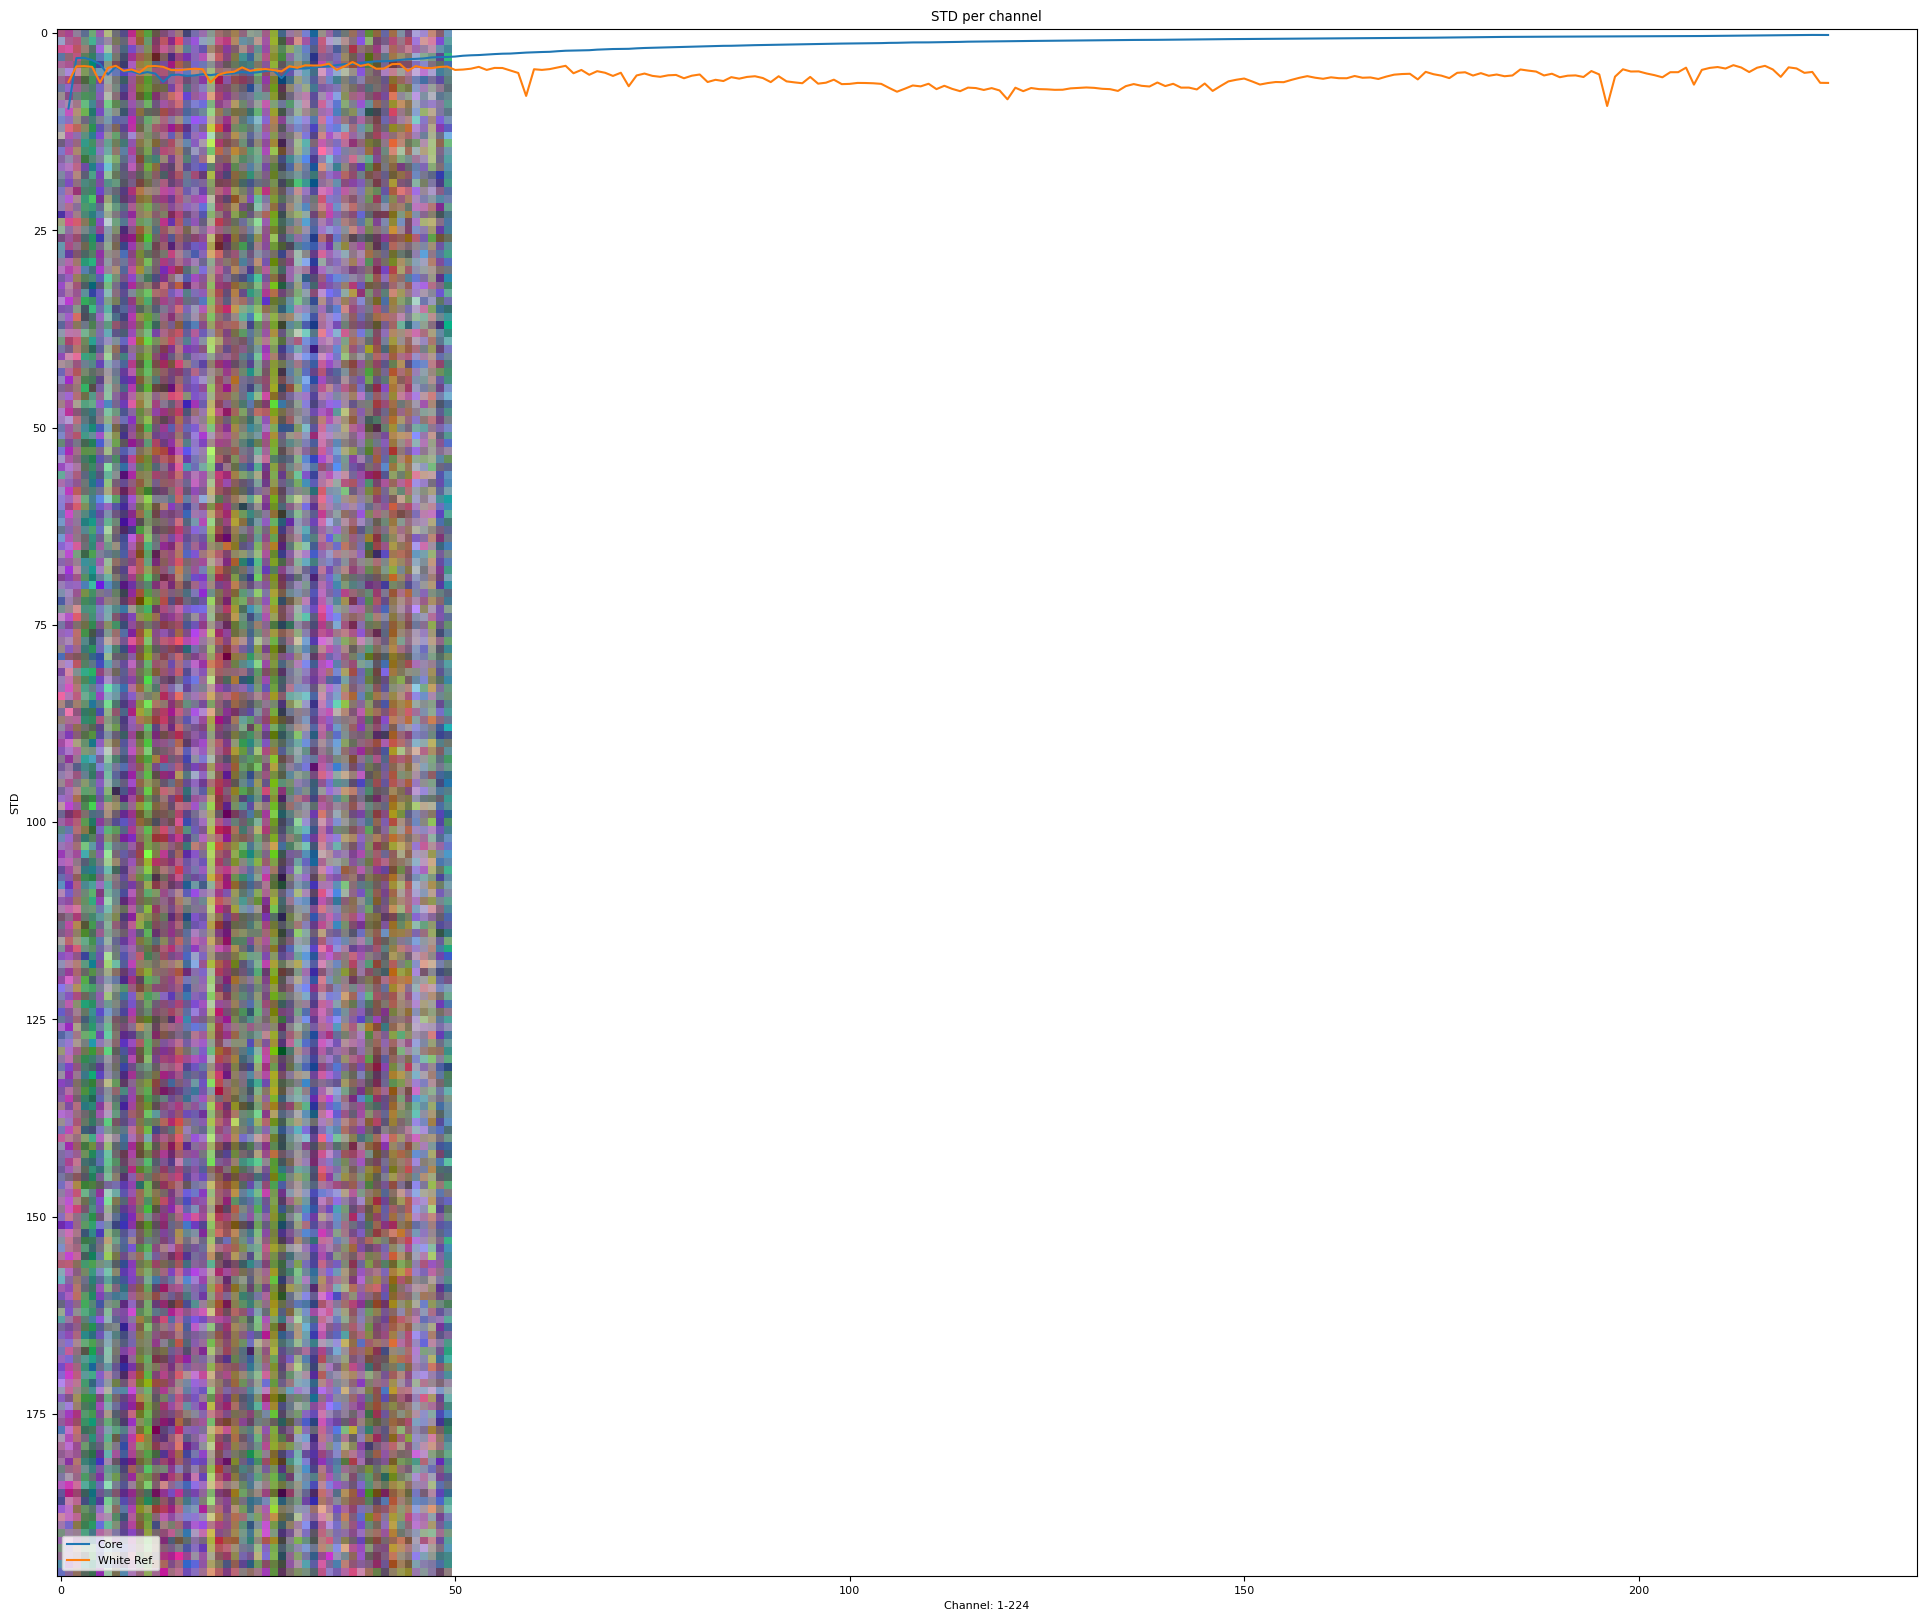

/Users/r.rumsey/src/stat/icespec/filter_bands_module.py:63: RuntimeWarning: invalid value encountered in sqrt
  SNR = np.sqrt(np.array(data_var)**2 / np.array(wht_var)**2 - 1)


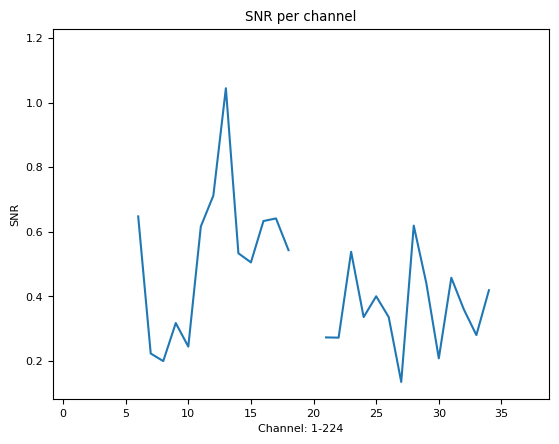

Bad Bands:  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 36, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223]
Shape Before:  (500, 50, 224)
Shape After:  (500, 50, 177)
Flattened shape:  (25000, 177)
Valid Data shape:  (25000, 177)
pca shape:  (25000, 5)
Rematrix shape:  (500, 50, 5)


/Applications/anaconda3/envs/HSIenv/lib/python3.12/site-packages/spectral/graphics/spypylab.py:796: UserWarning: Failed to create RectangleSelector object. Interactive pixel class labeling will be unavailable.
  warnings.warn(msg)
/Users/r.rumsey/src/stat/icespec/icespec_process1_module.py:145: UserWarning: Possible precision loss converting image of type float64 to uint8 as required by rank filters. Convert manually using skimage.util.img_as_ubyte to silence this warning.
  equalized = equalizer.analyze_data(image)


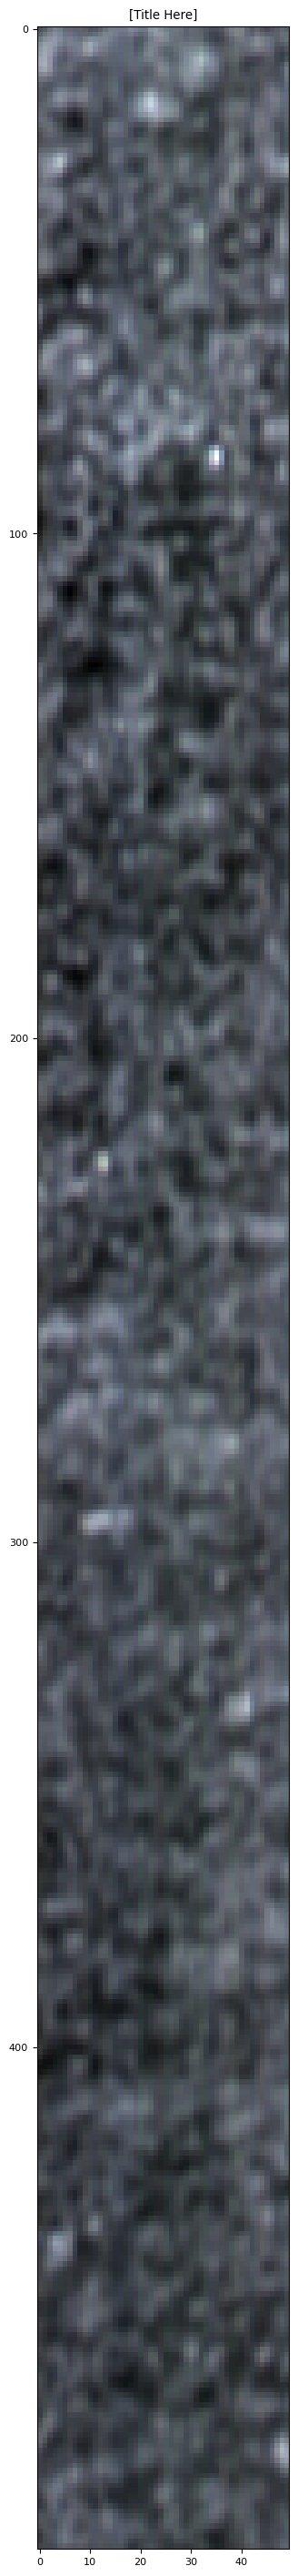

<Figure size 2400x3600 with 0 Axes>

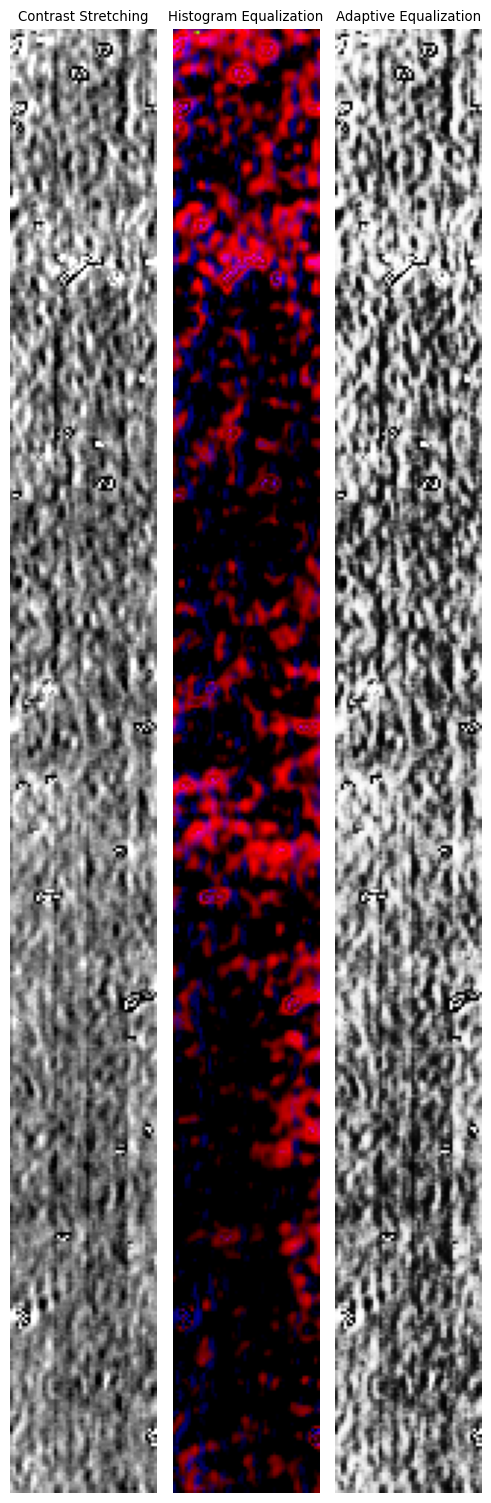

In [6]:
data_nparr, w_ref, d_ref, fwhm = processice.getEnviData(dataPath, Debug)

# dataSize, stdSize = getSize.retrieveData(DataFrame, Row)
trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize, Debug=True) #return arr of 3 trimmed
correctedData = processice.reflectance(trimmedData, Debug)
filtered_img = processice.remove_bands(correctedData, trimmedData[1])
previewed_img = processice.previewImg(filtered_img, "[Title Here]")

inpainted_img = processice.bubbles(filtered_img,  fwhm)
inpainted_arr = np.array(inpainted_img)

flattened_img = processice.flatten_data(inpainted_arr)
flattened_arr = np.array(flattened_img)


rematrix_img = processice.resize_matrix(flattened_img, trimmedData, pc_num = 5) #pc_num can be changed
eq_img = processice.equalize(rematrix_img)



In [7]:
#processice.preview(trimmedData[0], correctedData)

In [8]:
# for data in datasetPaths:
#     data_nparr, w_ref, d_ref = processice.getEnviData(data)
#     dataSize, stdSize = getSize.retrieveData(DataFrame, Row)
#     trimmedData = processice.trim(data_nparr, w_ref, d_ref, dataSize, stdSize) #return arr of 3 trimmed
#     correctedData = processice.reflectance(trimmedData)
#     pca_img = processice.components(correctedData)
#     processice.preview(trimmedData[0], correctedData)
#     equalizedData = processice.equalize(pca_img)
#     morphedData = processice.morphin(correctedData)